In [2]:
# main sources: https://github.com/KDMStromback/mm-fit/blob/master/EDA.ipynb

import os
import numpy as np
from utils import utils
from utils import plotting

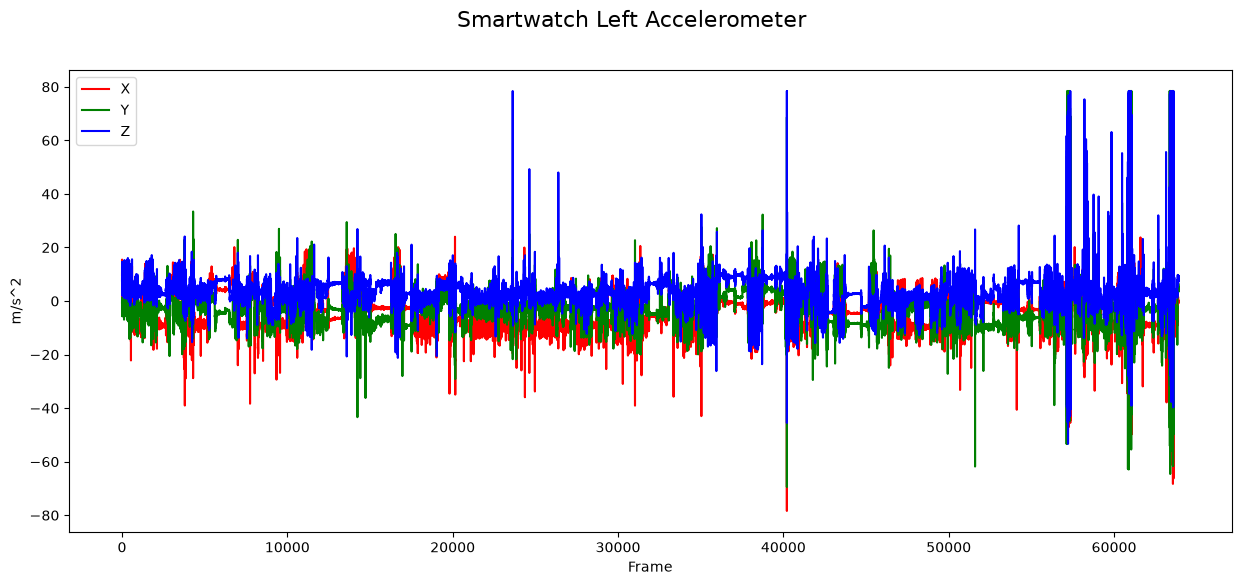

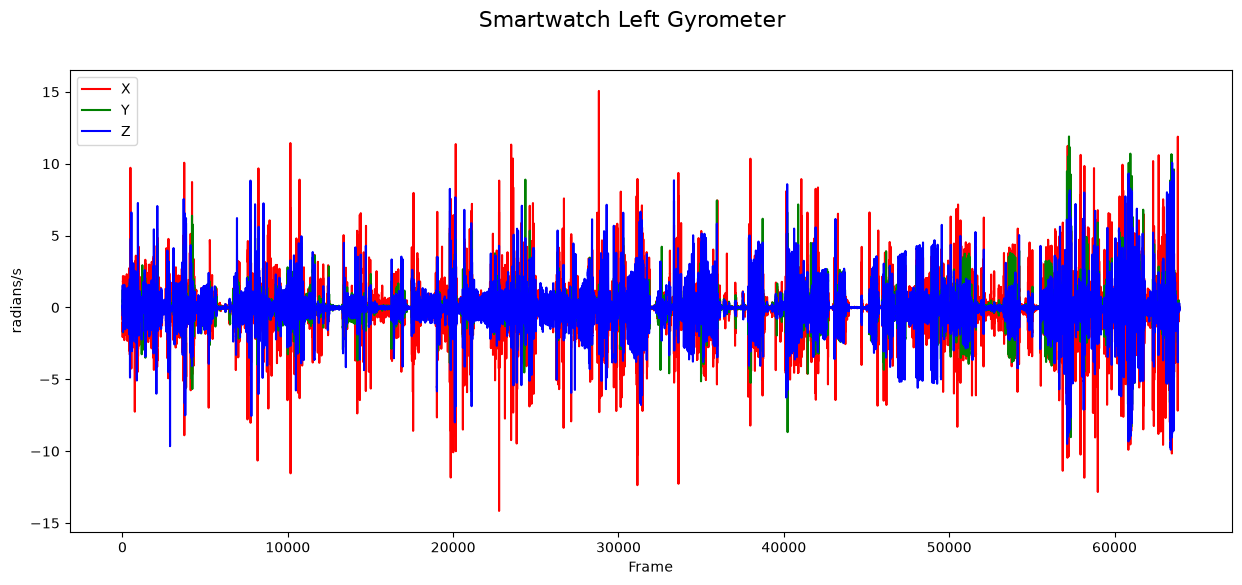

In [3]:
# Load data for a workout
w_id = 'w00'
data_dir = os.path.join('mm-fit/', w_id)

# Load modalities
modalities = {}
modalities['sw_l_acc'] = utils.load_modality(os.path.join(data_dir, w_id + '_sw_l_acc.npy')) # smartwatch left accelerometer
modalities['sw_l_gyr'] = utils.load_modality(os.path.join(data_dir, w_id + '_sw_l_gyr.npy')) # smartwatch left accelerometer

# Filter out modalities with None value, i.e. that do not exist
modalities = {k: v for k, v in modalities.items() if v is not None}

# Load labels
labels = utils.load_labels(os.path.join(data_dir, w_id + '_labels.csv'))

# Plot a few sensor modalities from the smartwatch device result
plotting.plot_sensor(modalities['sw_l_acc'], data_type='acc', title='Smartwatch Left Accelerometer', overlay=True)
plotting.plot_sensor(modalities['sw_l_gyr'], data_type='gyr', title='Smartwatch Left Gyrometer', overlay=True)

Label: squats
Repetitions: 10
sw_l_acc (220297, 5)


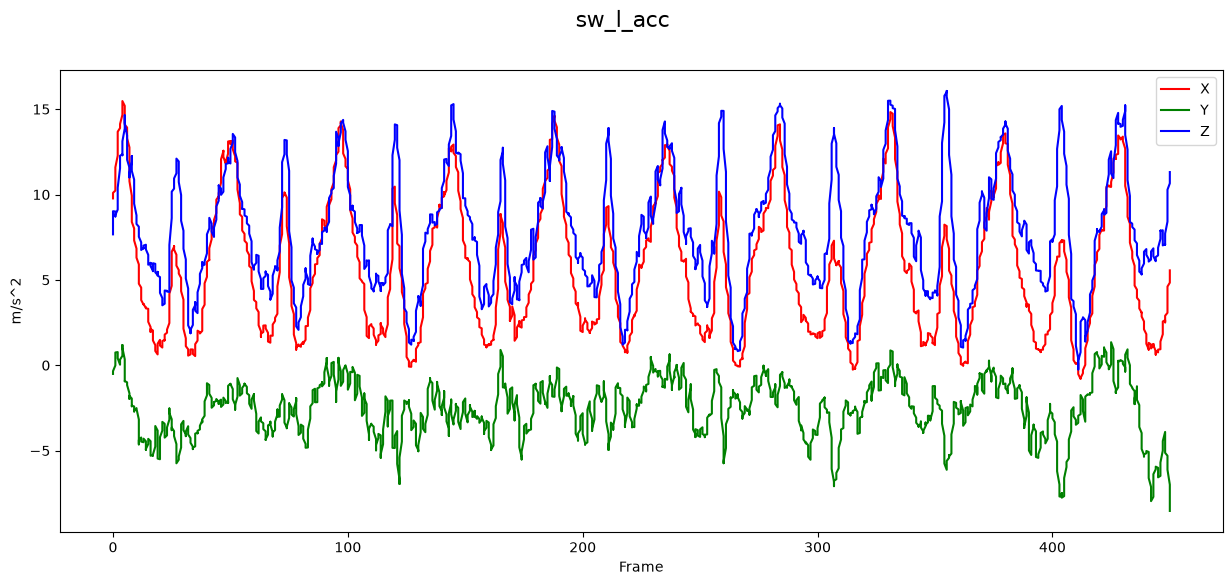

sw_l_gyr (220297, 5)


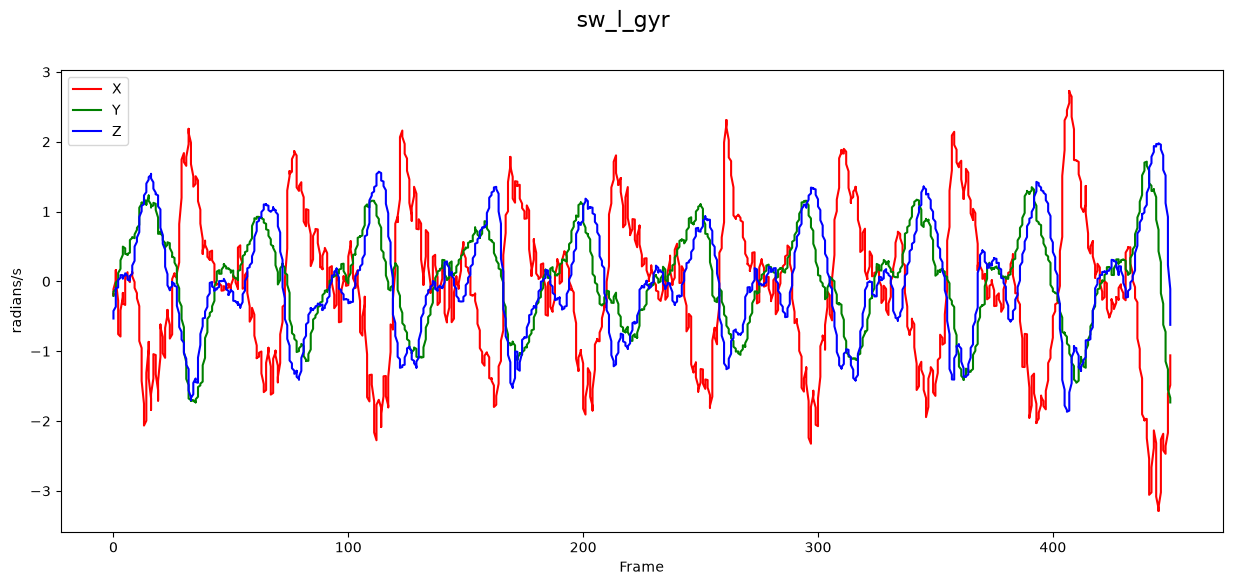

Label: squats
Repetitions: 10
sw_l_acc (220297, 5)


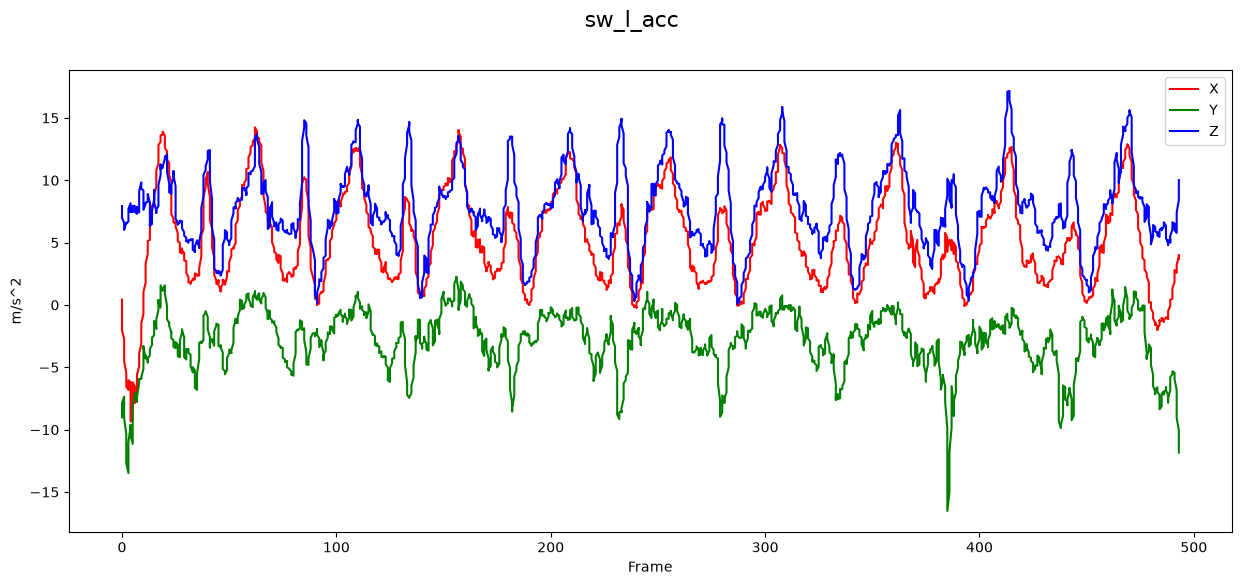

sw_l_gyr (220297, 5)


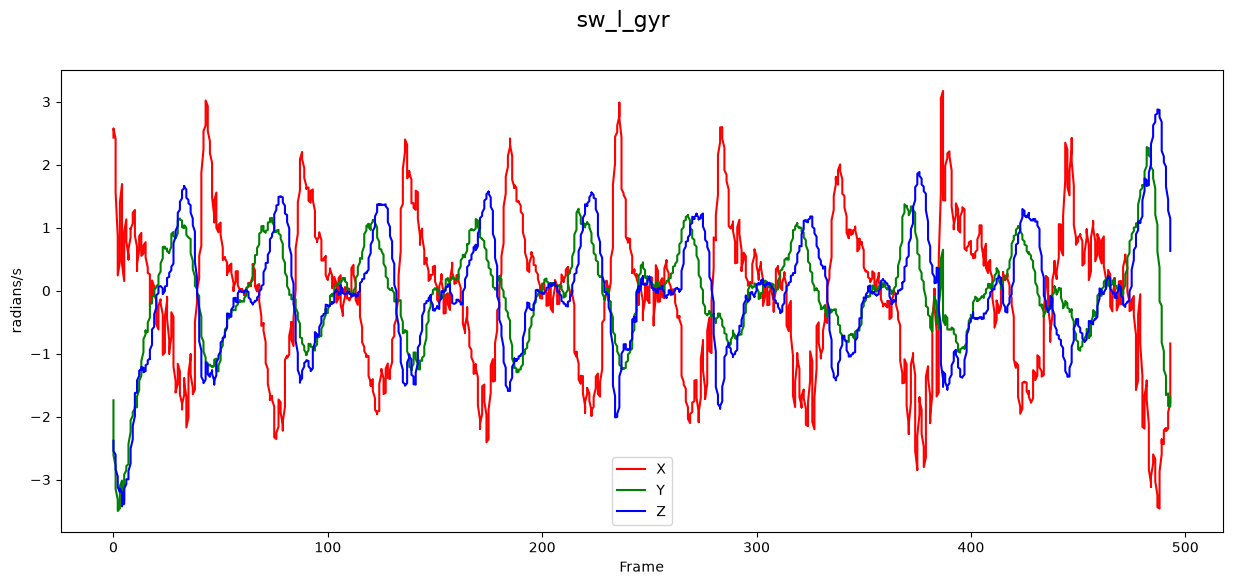

In [4]:
# Plot all modalities for a set of squats
for label in labels[0:2]:
    print('Label: {}'.format(label[3]))
    print('Repetitions: {}'.format(label[2]))
    for mod_type, mod_data in modalities.items():
        mod_subset = utils.get_subset(mod_data, start=label[0], end=label[1])
        print(mod_type, mod_data.shape)
        if mod_type == 'pose_2d':
            plotting.plot_joints(mod_subset, dim=2, joints=[1])
        elif mod_type == 'pose_3d':
            plotting.plot_joints(mod_subset, dim=3, joints=[1])
        else:
            if 'acc' in mod_type:
                data_type = 'acc'
            elif 'gyr' in mod_type:
                data_type = 'gyr'
            elif 'mag' in mod_type:
                data_type = 'mag'
            else:
                data_type = 'hr'
            plotting.plot_sensor(mod_subset, data_type=data_type, title=mod_type, overlay=True)   